In [1]:
%load_ext autoreload
%autoreload 2

import os
import pickle
import sys 

import ipywidgets as widgets
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from dotenv import load_dotenv
from ipywidgets import interact

from gene_regulatory.grn_path_scoring import possible_pathways, score_paths_all, setup_graph, up_or_down
from gene_regulatory.gse import get_gene_sets
from utils.notebook_utils import *
from utils.plot_utils import plot_path_score_distributions
from utils.vis_utils import change_graph_ids, colour_path

load_dotenv(override=True)

pd.set_option("display.float_format", "{:.2f}".format)
ENV_OPTIONS = ["TAXID", "EXPRESSION_DATA", "VIRUS_NODE_PATH", "VIRUS_EDGE_PATH", "VIRUS_MAP", "PPI_PATH", 
               "PROTEIN_MAP", "GRN_PATH", "PATHWAY_FILE"]

print("Running with options:")
for option in ENV_OPTIONS:
    print(f"{option:<15}  {os.getenv(option)}")
    if option == "EXPRESSION_DATA":
        print()

Running with options:
TAXID            2697049
EXPRESSION_DATA  data/covid_set.csv

VIRUS_NODE_PATH  data/virus_nodes.csv
VIRUS_EDGE_PATH  data/interactions_annotated.biogrid.csv
VIRUS_MAP        data/sars_cov_2_gene_map.tsv
PPI_PATH         data/PPI.pkl
PROTEIN_MAP      data/mart_export.txt
GRN_PATH         data/grn_tf_ncbi
PATHWAY_FILE     data/reactome_pathways_lowest_filtered.csv


In [2]:
accessed = set()

def hook(event, args):
    if event == "open":
        path = args[0]
        if isinstance(path, (str, bytes, os.PathLike)):
            accessed.add(os.path.abspath(os.fsdecode(path)))
    elif event == "import":
        pass  # imports also trigger "open" on the .py/.pyc file
    elif event in ("subprocess.Popen", "os.system"):
        accessed.add(f"[EXEC] {args}")

sys.addaudithook(hook)

Removed 6731 nodes: 1,12,14,16,19
Removed 5622/18333 nodes
5622 nodes without exp, 0 are virus


Scoring viral graph: 100%|██████████| 12387/12387 [00:04<00:00, 2680.66nodes/s]


Scoring human only graph: 100%|██████████| 12706/12706 [00:04<00:00, 2987.65nodes/s]


Scoring random 0 graph: 100%|██████████| 12387/12387 [00:04<00:00, 2865.85nodes/s]


Scoring random 1 graph: 100%|██████████| 12387/12387 [00:04<00:00, 2850.69nodes/s]


Scoring random 2 graph: 100%|██████████| 12387/12387 [00:04<00:00, 2796.06nodes/s]


Scoring random 3 graph: 100%|██████████| 12387/12387 [00:04<00:00, 2970.76nodes/s]


Scoring random 4 graph: 100%|██████████| 12387/12387 [00:04<00:00, 2904.45nodes/s]


Cases with |ρ| > 0.449 survive BH correction


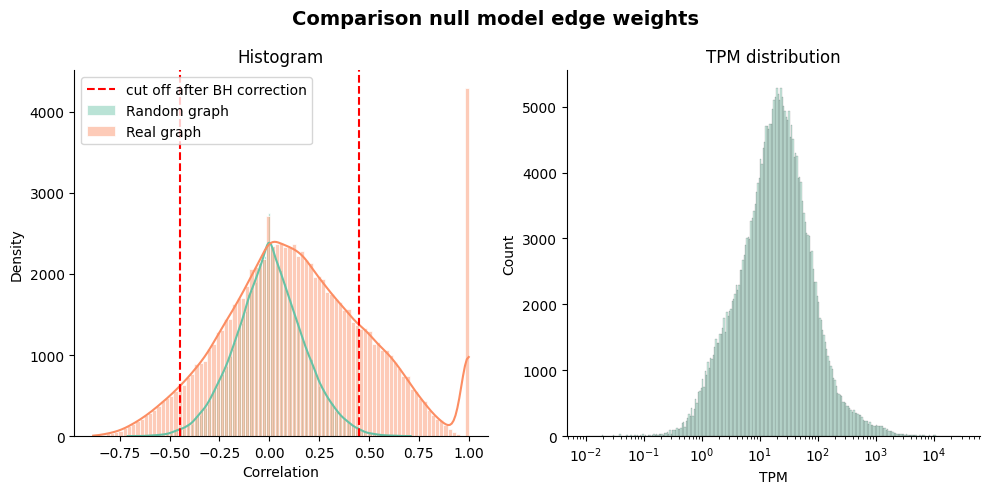

Removing 72,435 edges out of 97,531 total


Scoring paths to alert: 100%|██████████| 51/51 [00:54<00:00,  1.08s/it]


In [3]:
filter_graph, scored_graph, ho_scored_graph, virus_nodes = setup_graph(5, plus1=False, plot_weights=True)
all_info = score_paths_all(filter_graph, scored_graph, ho_scored_graph, virus_nodes, paths_only=True, max_path_len=4)

In [4]:
selected_alert = 0


def summarize(alert_node):
    return alert_node["node_name"]


all_info[0].keys()

dict_keys(['node_name', 'node_id', 'h_alert_graph', 'v_alert_graph', 'exclude', 'virus_paths', 'virus_scores', 'path_lengths', 'human_paths', 'human_scores'])

In [5]:
@interact(
    selected=widgets.ToggleButtons(
        options=[(f"{i}: {summarize(c)}\t{len(c["virus_paths"])}", i) for i, c in enumerate(all_info)],
        description=f"Pick an alert gene ({len(all_info)} total):",
        style={"description_width": "initial"},
    )
)
def show_case(selected):
    global selected_alert
    selected_alert = selected
    print("Alert is", selected_alert)
    return selected

interactive(children=(ToggleButtons(description='Pick an alert gene (34 total):', options=(('0: B2M\t274', 0),…

In [6]:
G = all_info[selected_alert]["v_alert_graph"]
colour_path(
    G,
    list({x for path in all_info[selected_alert]["virus_paths"] for x in path}),
    alert=all_info[selected_alert]["node_id"],
)
G = change_graph_ids(G)

anchor_nodes = [x for x, d in G.nodes(data=True) if d["is_virus"]]
init_pos = {node: (0, i + i) for i, node in enumerate(anchor_nodes)}

anchor_nodes.append(all_info[selected_alert]["node_name"])
init_pos[anchor_nodes[-1]] = (5, 0)

pos = nx.spring_layout(G.to_undirected(), fixed=anchor_nodes, pos=init_pos)

### Setup graph

In [7]:
weights = [d["weight"] if not G.nodes[u]["is_virus"] else 1 for u, _, d in G.edges(data=True)]
w_min, w_max = 0, max(weights)


def normalize_opacity(w, lo=0.3, hi=1.0):
    if w_max == w_min:
        return hi
    return lo + (w - w_min) / (w_max - w_min) * (hi - lo)

In [8]:
# EDGES
edge_annotations = []
for u, v, data in G.edges(data=True):
    x0, y0 = pos[u]
    x1, y1 = pos[v]
    edge_annotations.append(
        {
            "ax": x0,
            "ay": y0,
            "x": x1,
            "y": y1,
            "xref": "x",
            "yref": "y",
            "axref": "x",
            "ayref": "y",
            "showarrow": True,
            "arrowhead": 3,
            "arrowsize": 1.5,
            "arrowwidth": 1.5 + data["weight"] * 0.3,  # optional: thicker = heavier
            "arrowcolor": data["color"],
            "opacity": normalize_opacity(abs(data["real_weight"])),
            "standoff": 15,
            "startstandoff": 15,
        }
    )

weight_annotations = []
for u, v, data in G.edges(data=True):
    x0, y0 = pos[u]
    x1, y1 = pos[v]
    mx, my = (x0 + x1) / 2, (y0 + y1) / 2
    weight_annotations.append(
        {
            "x": mx,
            "y": my,
            "xref": "x",
            "yref": "y",
            "text": f"{data['real_weight']:.2f}",
            "showarrow": False,
            "font": {"size": 11, "color": "black"},
            "bgcolor": "rgba(255,255,255,0.7)",  # readability over crossing edges
            "yshift": 8,  # nudges label "above" the line
        }
    )

if len(list(G.nodes())) > 30:
    all_annotations = edge_annotations
else:
    all_annotations = edge_annotations + weight_annotations

In [9]:
# NODES
node_x = [pos[n][0] for n in G.nodes()]
node_y = [pos[n][1] for n in G.nodes()]
node_colors = [G.nodes[n]["color"] for n in G.nodes()]
node_text = list(G.nodes())

node_trace = go.Scatter(
    x=node_x,
    y=node_y,
    mode="markers+text",
    text=node_text,
    textposition="top center",
    marker={
        "size": 20,
        "color": node_colors,  # direct color values work if they're valid CSS colors
        "line": {"width": 2, "color": "black"},
    },
    hoverinfo="text",
)

### Show graph

In [10]:
fig = go.Figure(data=[node_trace])
fig.update_layout(
    annotations=all_annotations,
    showlegend=False,
    margin={"l": 20, "r": 20, "t": 20, "b": 20},
    xaxis={"showgrid": False, "zeroline": False, "showticklabels": False},
    yaxis={"showgrid": False, "zeroline": False, "showticklabels": False},
)
fig.show()

In [11]:
# vis only paths belonging to the pathway?
out = sankey_convert(all_info[selected_alert], scored_graph, top_n=100)
plot_sankey(out, all_info, selected_alert)

### Score genes in path

In [12]:
alert_paths, alert_genes, alert_gene_scores = nodes_per_path(all_info[selected_alert], scored_graph)

alert_genes = dict(sorted(alert_genes.items(), key=lambda x: x[1], reverse=True))
alert_gene_degrees = {g: scored_graph.degree[get_node_by_name(scored_graph, g)] for g in alert_genes}

v_df = alert_genes_to_df(alert_genes, alert_gene_scores, alert_paths).sort_values(
    by=["n_paths", "avg_score"], ascending=False
)
v_df.round(2)

,Gene,n_paths,pct_included,avg_score
0,B2M,274,100.00,0.62
1,SP1,159,58.03,0.62
2,S (v),95,34.67,0.63
3,N (v),75,27.37,0.63
4,EP300,57,20.80,0.64
...,...,...,...,...
72,TCF12,1,0.36,0.66
69,KLF4,1,0.36,0.66
70,POLR2G,1,0.36,0.64
68,HTT,1,0.36,0.61


In [13]:
ho_alert_paths, ho_alert_genes, ho_alert_gene_score = nodes_per_path(all_info[selected_alert], ho_scored_graph, "human")

ho_alert_genes = dict(sorted(ho_alert_genes.items(), key=lambda x: x[1], reverse=True))
ho_alert_gene_degrees = {g: ho_scored_graph.degree[get_node_by_name(ho_scored_graph, g)] for g in ho_alert_genes}

alert_genes_to_df(ho_alert_genes, ho_alert_gene_score, ho_alert_paths).sort_values(
    by=["n_paths", "avg_score"], ascending=False
).round(2)

,Gene,n_paths,pct_included,avg_score
0,IRF7,275,100.00,0.41
1,B2M,275,100.00,0.41
2,NFKB1,78,28.36,0.38
3,SP1,72,26.18,0.38
4,STAT1,41,14.91,0.49
...,...,...,...,...
183,RBBP4,1,0.36,0.29
184,NKX2-1,1,0.36,0.28
185,TBP,1,0.36,0.28
186,HDAC2,1,0.36,0.28


### All paths combined

In [14]:
passed_genes = {}
total_paths = 0
total_scores = {}
for an in all_info:
    path_update, paths_genes, paths_scores = nodes_per_path(an, scored_graph)
    total_paths += path_update
    passed_genes = merge_sum(passed_genes, paths_genes)
    total_scores = merge_sum(total_scores, paths_scores)

passed_genes = dict(sorted(passed_genes.items(), key=lambda x: x[1], reverse=True))
total_degree = {g: scored_graph.degree[get_node_by_name(scored_graph, g)] for g in passed_genes}

tries = 1000
node_importance = random_paths(scored_graph, tries=tries, add_pseudo=True)

node_means = {k: np.mean(v) for k, v in node_importance.items()}
node_std = {k: np.std(v, ddof=1) for k, v in node_importance.items()}

df = alert_genes_to_df(passed_genes, total_scores, total_paths).sort_values(
    by=["n_paths", "avg_score"], ascending=False
)

df["node_id"] = df.apply(lambda x: get_node_by_name(scored_graph, x["Gene"]), axis=1)
df["z_score"] = df.apply(
    lambda x: z_score(x["pct_included"] / 100, node_means[x["node_id"]], node_std[x["node_id"]]), axis=1
)
df.set_index("node_id", inplace=True)
df.sort_values(by=["z_score", "n_paths"], ascending=False).round(2)

,Gene,n_paths,pct_included,avg_score,z_score
node_id,,,,,
43740570,E (v),625,15.02,0.62,4.72
43740575,N (v),1325,31.85,0.62,4.45
43740568,S (v),1389,33.39,0.62,4.25
4637,MYL6,469,11.27,0.62,3.54
2597,GAPDH,460,11.06,0.60,2.43
...,...,...,...,...,...
1386,ATF2,37,0.89,0.66,-0.19
5970,RELA,142,3.41,0.60,-0.19
5914,RARA,2,0.05,0.52,-0.20


### Mach pathways to paths

In [15]:
gene_sets, pathway_sets, pathway_names = get_gene_sets(os.getenv("PATHWAY_FILE"))

In [16]:
print(ho_scored_graph)
print(scored_graph)

DiGraph with 12706 nodes and 94064 edges
DiGraph with 12387 nodes and 25096 edges


In [17]:
poss_pathways = possible_pathways(scored_graph, gene_sets, {i["node_id"] for i in all_info}, fixed=False)

for pw in poss_pathways:
    print(pathway_names[pw], poss_pathways[pw])
print(len(poss_pathways))

100%|██████████| 2223/2223 [00:00<00:00, 102893.91it/s]

ISG15 antiviral mechanism 2
SMAD2/SMAD3:SMAD4 heterotrimer regulates transcription 8
Constitutive Signaling by NOTCH1 PEST Domain Mutants 4
Constitutive Signaling by NOTCH1 HD+PEST Domain Mutants 4
Interferon gamma signaling 23
Interferon alpha/beta signaling 205
SARS-CoV-2 activates/modulates innate and adaptive immune responses 50
Regulation of MITF-M-dependent genes involved in pigmentation 2
PKR-mediated signaling 1
9


In [18]:
def get_regulation(graph, gene_set):
    affected = []
    for gene in gene_set[0]:
        x = graph.nodes[gene]["time"]
        y = graph.nodes[gene]["timepoints"]
        slope = up_or_down(x, y)
        affected.append(slope)
    if all(slope > 0 for slope in affected):
        return "upregulated"
    elif all(slope < 0 for slope in affected):
        return "downregulated"
    else:
        return "mixed"

In [19]:
virus_path_sets = set()
pathway_num = {}
pw_regulation = {}
v_identified = 0
v_total_paths = 0
v_hits = 0
al_paths = {}
v_pathway_names = {}
for al in range(len(all_info)):
    v_path_set, non_trivial, v_hit, v_paths = find_pathways(
        al, all_info, gene_sets, pathway_names, source="virus", longest_path=False, all_but=0
    )
    all_id_pathways = [pw for detected in v_path_set.values() for pw in detected]
    v_identified += len(all_id_pathways)
    v_total_paths += non_trivial
    v_hits += v_hit
    virus_path_sets.update(set(all_id_pathways))
    for pw in all_id_pathways:
        if pw not in pathway_num:
            pathway_num[pw] = 0
        pathway_num[pw] += 1
        if pw not in pw_regulation:
            pw_regulation[pw] = get_regulation(scored_graph, v_paths[pw])
        al_paths[all_info[al]["node_id"]] = v_paths

for pw in virus_path_sets:
    print(pathway_names[pw], f"({pw_regulation[pw]})", pathway_num[pw])
    v_pathway_names[pw] = pathway_names[pw]
print(v_identified, v_total_paths, v_hits, f"{(v_hits / v_total_paths) * 100:.2f}%", len(virus_path_sets))

ISG15 antiviral mechanism (upregulated) 2
SARS-CoV-2 activates/modulates innate and adaptive immune responses (upregulated) 18
Interferon alpha/beta signaling (upregulated) 96
SMAD2/SMAD3:SMAD4 heterotrimer regulates transcription (mixed) 2
PKR-mediated signaling (upregulated) 1
Interferon gamma signaling (upregulated) 6
125 2318 112 4.83% 6


In [20]:
human_path_sets = set()
h_identified = 0
h_total_paths = 0
h_hits = 0
for al in range(len(all_info)):
    v_path_set, non_trivial, h_hit, h_paths = find_pathways(
        al, all_info, gene_sets, pathway_names, source="human", longest_path=False, all_but=0
    )
    all_id_pathways = [pw for detected in v_path_set.values() for pw in detected]
    h_identified += len(all_id_pathways)
    h_total_paths += non_trivial
    h_hits += h_hit
    human_path_sets.update(set(all_id_pathways))
    for pw in all_id_pathways:
        if pw not in pw_regulation:
            pw_regulation[pw] = get_regulation(ho_scored_graph, h_paths[pw])

for pw in human_path_sets:
    print(pathway_names[pw], f"({pw_regulation[pw]})")
print(h_identified, h_total_paths, h_hits, f"{(h_hits / h_total_paths) * 100:.2f}%")

SARS-CoV-2 activates/modulates innate and adaptive immune responses (upregulated)
Interferon alpha/beta signaling (upregulated)
PKR-mediated signaling (upregulated)
Interferon gamma signaling (upregulated)
86 4194 83 1.98%


In [21]:
## pathway quality
all_virus_scores = get_all_scores(all_info)
all_human_scores = get_all_scores(all_info, "human")

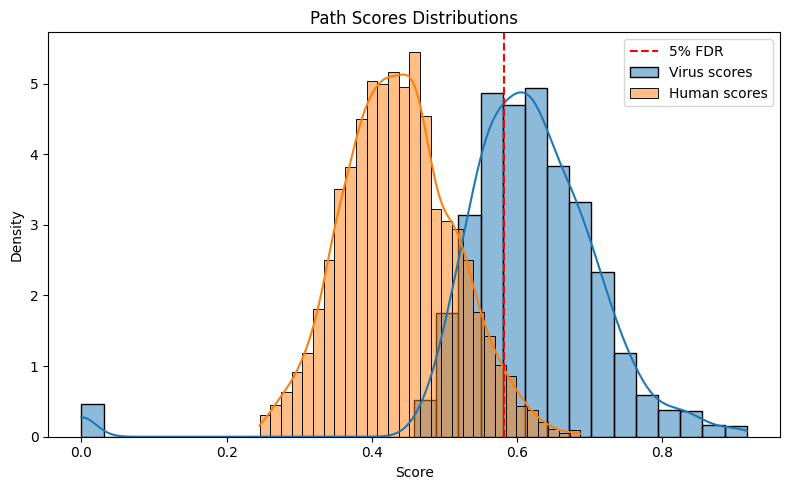

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Path Scores Distributions'}, xlabel='Score', ylabel='Density'>)

In [22]:
path_cutoff, _ = find_fdr_cutoff(all_human_scores, all_virus_scores)

plot_path_score_distributions(all_virus_scores, all_human_scores, path_cutoff)

In [23]:
bst_pathway_scores = {}
total_scores = 0
for p_node in al_paths:
    for pw in al_paths[p_node]:
        for path in al_paths[p_node][pw]:
            score = get_path_score(all_info, path)
            total_scores += 1
            if pw not in bst_pathway_scores:
                bst_pathway_scores[pw] = []
            bst_pathway_scores[pw].append(score)

avg_score = sum(all_virus_scores) / len(all_virus_scores)
pw_names = [pathway_names[pw] for pw in bst_pathway_scores]
total_paths = [len(bst_pathway_scores[pw]) for pw in bst_pathway_scores]
clear_thresh = [sum(score > path_cutoff for score in bst_pathway_scores[pw]) / len(bst_pathway_scores[pw]) for pw in bst_pathway_scores]

df = pd.DataFrame({"pathway_id": bst_pathway_scores.keys(), "pathway_name": pw_names, "pathway_num": total_paths, "% above thresh": clear_thresh})
df = df.sort_values(by="pathway_num", ascending=False)
df["% above thresh"] = df["% above thresh"] * 100
df["% above thresh"] = df["% above thresh"].astype(int)

df

,pathway_id,pathway_name,pathway_num,% above thresh
2,R-HSA-909733,Interferon alpha/beta signaling,96,100
0,R-HSA-9705671,SARS-CoV-2 activates/modulates innate and adap...,18,100
1,R-HSA-877300,Interferon gamma signaling,6,100
3,R-HSA-2173796,SMAD2/SMAD3:SMAD4 heterotrimer regulates trans...,2,0
4,R-HSA-1169408,ISG15 antiviral mechanism,2,100
5,R-HSA-9833482,PKR-mediated signaling,1,100


In [24]:
extra_paths = {"path": [], "score": [], "alert": [], "source": [], "path_name": [], "in_pathway": []}
for al in all_info:
    for p, s in zip(al["virus_paths"], al["virus_scores"]):
        if s < path_cutoff:
            continue
        if p[1:] in extra_paths["path"]:
            p_idx = extra_paths["path"].index(p[1:])
            extra_paths["source"][p_idx] = f"{extra_paths["source"][p_idx]}," + str(p[0])
            continue

        if p[0] == 6772:
            print(p)
            raise ValueError

        if p[-1] not in al_paths:
            extra_paths["in_pathway"].append("")
        else:
            pws = []
            pa = tuple(int(x) for x in p[1:])
            for pw in al_paths[pa[-1]]:
                if pa in al_paths[pa[-1]][pw]:
                    pws.append(pw)
            extra_paths["in_pathway"].append(",".join(pws))

        

        extra_paths["path"].append([int(x) for x in p[1:]])
        extra_paths["path_name"].append(",".join([scored_graph.nodes[x]["name"] for x in p[1:]]))
        extra_paths["alert"].append(al["node_id"])
        extra_paths["source"].append(p[0])
        extra_paths["score"].append(s)

df = pd.DataFrame(extra_paths)

In [25]:
df[(df["in_pathway"] != "") & (df["in_pathway"] != "R-HSA-909733")]
#df

,path,score,alert,source,path_name,in_pathway
6,"[6772, 3665, 567]",0.80,567,"43740570,43740575,43740568","STAT1,IRF7,B2M","R-HSA-9705671,R-HSA-877300"
12,"[6772, 6773, 3665, 567]",0.83,567,"43740570,43740575,43740568","STAT1,STAT2,IRF7,B2M",R-HSA-9705671
13,"[6772, 10379, 3665, 567]",0.75,567,"43740570,43740575,43740568","STAT1,IRF9,IRF7,B2M",R-HSA-877300
59,"[6773, 3665, 567]",0.79,567,"43740575,43740568","STAT2,IRF7,B2M",R-HSA-9705671
60,"[6773, 6772, 3665, 567]",0.84,567,"43740575,43740568","STAT2,STAT1,IRF7,B2M",R-HSA-9705671
69,"[1387, 6773, 3665, 567]",0.73,567,43740575,"CREBBP,STAT2,IRF7,B2M",R-HSA-9705671
588,"[6772, 3659, 4261, 3106]",0.67,3106,"43740570,43740575,43740568","STAT1,IRF1,CIITA,HLA-B",R-HSA-877300
589,"[6772, 4261, 3106]",0.59,3106,"43740570,43740575,43740568","STAT1,CIITA,HLA-B",R-HSA-877300
597,"[6772, 6773, 3106]",0.78,3106,"43740570,43740575,43740568","STAT1,STAT2,HLA-B","R-HSA-909733,R-HSA-9705671"
648,"[6773, 6772, 3106]",0.83,3106,"43740575,43740568","STAT2,STAT1,HLA-B","R-HSA-909733,R-HSA-9705671"


In [26]:
from scipy.stats import fisher_exact

table = [[v_hits, v_total_paths - v_hits], [h_hits, h_total_paths - h_hits]]
odds_ratio, p_val = fisher_exact(table)

print(odds_ratio, p_val)

2.5146752012583424 3.933459620452458e-10


In [27]:
def write_summary(alert_gene_id, alert_gene_name, scored_path_genes, p_val, virus_pathways, human_pathways):
    summary = {"alert_genes": alert_gene_id, 
               "alert_names": alert_gene_name, 
               "scored_path_df": scored_path_genes,
               "p_val": p_val,
               **virus_pathways,
               **human_pathways}
    pickle.dump(summary, open("data/multi_path_summary_cov_big_shuffle.pkl", "wb"))

# write_summary([i["node_id"] for i in all_info],
#               [i["node_name"] for i in all_info],
#               df,
#               p_val,
#               {"v_total_paths": v_total_paths,
#                "v_hits": v_hits,
#                "v_paths": al_paths,
#                "v_pathways": [f"{pathway_names[pw]} ({pw_regulation[pw]})" for pw in virus_path_sets],
#                "v_pathway_names": v_pathway_names,
#               },
#                {"h_total_paths": h_total_paths,
#                 "h_hits": h_hits,
#                 "h_pathways": [f"{pathway_names[pw]} ({pw_regulation[pw]})" for pw in human_path_sets]})